# Taş-Kağıt-Makas El Hareketi Sınıflandırma (CNN)
**Makine öğrenmesi ile probleme uygun çözüm geliştirme — Derin öğrenme / görüntü sınıflandırma**

Bu not defterindeki bölüm numaraları, proje yönergesindeki zorunlu adımlarla (3.1 – 3.8) aynıdır:

| Bölüm | Yönerge maddesi |
|---|---|
| 1 | 3.1 Problem tanımı |
| 2 | 3.2 Veri setinin tanıtılması |
| 3 | 3.3 Veri keşfi (3 inceleme) |
| 4 | 3.4 Veri ön işleme |
| 5 | 3.5 Model seçimi / tasarımı |
| 6 | 3.6 Model eğitimi |
| 7 | 3.7 Model değerlendirme |
| 8 | 3.8 Sonuçların yorumlanması ve hata analizi |
| 9 | Sonuç ve geliştirme önerileri |

> **Not:** Aşağıdaki yorumlardaki sayılar, bu not defterinin kayıtlı çıktılarına aittir. Hücreleri yeniden çalıştırırsan (rastgelelik nedeniyle) rakamlar küçük farklarla değişir; o durumda yorumlardaki sayıları da güncelle.

---
## 1. Problem Tanımı (Yönerge 3.1)

Bu projede, bir el fotoğrafına bakarak elin **taş (rock)**, **kağıt (paper)** ya da **makas (scissors)** şeklini gösterdiğini otomatik olarak tahmin eden bir model geliştirilmiştir.

- **Girdi:** 300x300 piksel boyutunda renkli (RGB) el görüntüsü.
- **Hedef çıktı:** Üç sınıftan biri: `rock`, `paper`, `scissors`.
- **Problem türü:** Üç sınıflı, çok sınıflı görüntü sınıflandırma. Görüntü verisi olduğu için evrişimli sinir ağı (CNN) kullanılmıştır.
- **Gerçek dünya ihtiyacı:** El hareketlerinin kamerayla otomatik tanınması; jest tabanlı oyunlarda, etkileşimli uygulamalarda ve dokunmadan kontrol edilen arayüzlerde temel bir bileşendir. Bu proje, böyle bir sistemin küçük ölçekli bir prototipidir.

### Ortam kurulumu
TensorFlow Datasets bazı Colab ortamlarında `importlib_resources` paketini bulamayabilir. Bu hücre, veri setini yüklerken hata almamak için o paketi kurar. **Diğer hücrelerden önce çalıştırılmalıdır.**

In [17]:
# Eksik paketi kur (sessiz mod: -q)
!pip install -q importlib_resources

---
## 2. Veri Seti (Yönerge 3.2)

| Özellik | Değer |
|---|---|
| **Veri seti** | Rock, Paper, Scissors |
| **Yazar / yıl** | Laurence Moroney, 2019 |
| **Kaynak (bağlantı)** | http://laurencemoroney.com/rock-paper-scissors-dataset |
| **Erişim yolu** | TensorFlow Datasets: `tfds.load("rock_paper_scissors")` |
| **Eğitim örneği** | 2.520 görüntü |
| **Test örneği** | 372 görüntü |
| **Görüntü boyutu** | 300 x 300 x 3 (RGB, uint8) |
| **Sınıflar / hedef değişken** | `rock` (0), `paper` (1), `scissors` (2) |
| **Sınıf dengesi** | Tam dengeli: eğitimde 840'ar, testte 124'er görüntü |
| **Lisans** | Veri setinin lisans ve kullanım koşulları, kaynak sayfasından kontrol edilmelidir |

Hedef değişken, görüntünün etiketidir (tam sayı: 0, 1, 2). Başka bir özellik sütunu yoktur; özellikler görüntünün pikselleridir.

Veri seti hazır ve açık bir veri setidir; kişisel veya hassas veri içermez. Aşağıdaki hücre veri setini indirir ve sınıf adlarıyla örnek sayılarını yazdırır.

In [16]:
# --- Kütüphaneler ve veri seti ---
# tfds.load: veri setini indirir ve hazır "train" / "test" ayrımıyla getirir.
# as_supervised=True: her örnek (görüntü, etiket) çifti olarak gelir.
# with_info=True: sınıf adları ve örnek sayıları gibi bilgileri 'info' nesnesinde verir.

import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt

(ds_train, ds_test), info = tfds.load(
    "rock_paper_scissors",
    split=["train", "test"],
    as_supervised=True,
    with_info=True,
)

print("Sınıflar:", info.features["label"].names)
print("Eğitim görüntüsü:", info.splits["train"].num_examples)
print("Test görüntüsü:", info.splits["test"].num_examples)

Sınıflar: ['rock', 'paper', 'scissors']
Eğitim görüntüsü: 2520
Test görüntüsü: 372


---
## 3. Veri Keşfi (Yönerge 3.3)
Yönerge en az 3 anlamlı inceleme ve yorum istiyor. Burada üç inceleme yapılmıştır: **(1)** örnek görüntüler, **(2)** sınıf dağılımı, **(3)** sınıf başına ortalama görüntü.

### 3.1 Örnek görüntüler
Eğitim setinden rastgele 9 görüntü ve etiketleri çizilir.

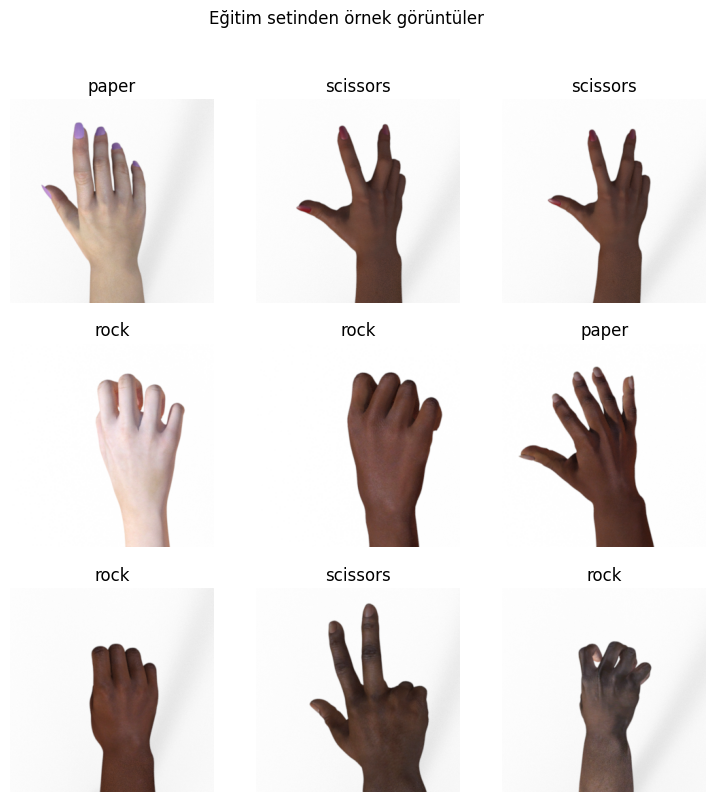

Görüntü boyutu: (300, 300, 3)


In [18]:
# --- İnceleme 1: Rastgele 9 eğitim görüntüsü ---
# shuffle(...).take(9): veriyi karıştırıp ilk 9 örneği alır (seed=42 ile tekrarlanabilir).

class_names = info.features["label"].names

plt.figure(figsize=(9, 9))
for i, (image, label) in enumerate(ds_train.shuffle(1000, seed=42).take(9)):
    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(class_names[label.numpy()])
    plt.axis("off")
plt.suptitle("Eğitim setinden örnek görüntüler")
plt.show()

print("Görüntü boyutu:", image.shape)

**Gözlem 1 (örnek görüntüler):**
- Arka plan sade ve açık renklidir; el görüntünün ortasında tek nesnedir. Bu, modelin işini kolaylaştıran bir durumdur.
- Eller farklı ten renklerinde ve farklı açılarda/duruşlardadır.
- Görüntüler, gerçek fotoğraftan çok bilgisayarda üretilmiş (render) izlenimi vermektedir. Bu bir gözlemdir; kaynakta ayrıca doğrulanmamıştır. Gerçek dünyadaki kamera görüntülerinde (karmaşık arka plan, ışık değişimi) model başarısının düşebileceği akılda tutulmalıdır.
- Görüntü boyutu `(300, 300, 3)` olarak doğrulanmıştır.

### 3.2 Sınıf dağılımı
Sınıflar dengesiz olsaydı (örneğin birinden çok az olsaydı) accuracy metriği yanıltıcı olurdu. Bu yüzden her sınıftaki görüntü sayısı sayılır.

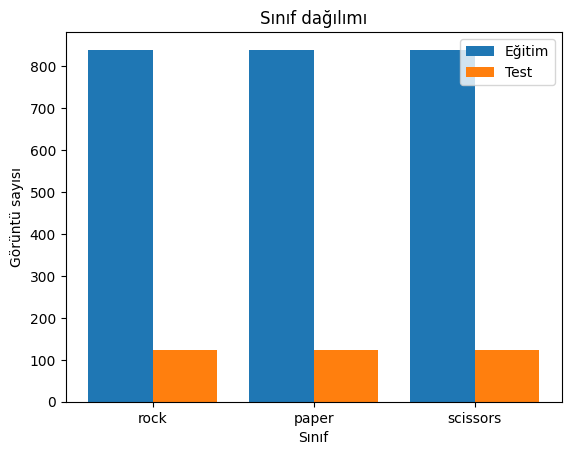

Eğitim: {'rock': 840, 'paper': 840, 'scissors': 840}
Test: {'rock': 124, 'paper': 124, 'scissors': 124}


In [19]:
# --- İnceleme 2: Sınıf dağılımı (eğitim ve test) ---
# Counter ile her etiketin kaç kez geçtiği sayılır, çubuk grafiğiyle gösterilir.

from collections import Counter

def sinif_say(ds):
    sayac = Counter(int(label.numpy()) for _, label in ds)
    return [sayac[i] for i in range(3)]

egitim_sayilari = sinif_say(ds_train)
test_sayilari = sinif_say(ds_test)

x = np.arange(3)
plt.bar(x - 0.2, egitim_sayilari, width=0.4, label="Eğitim")
plt.bar(x + 0.2, test_sayilari, width=0.4, label="Test")
plt.xticks(x, class_names)
plt.xlabel("Sınıf")
plt.ylabel("Görüntü sayısı")
plt.title("Sınıf dağılımı")
plt.legend()
plt.show()

print("Eğitim:", dict(zip(class_names, egitim_sayilari)))
print("Test:", dict(zip(class_names, test_sayilari)))

**Gözlem 2 (sınıf dağılımı):**
- Eğitim setinde her sınıftan **840**, test setinde **124** görüntü vardır; veri seti **tam dengelidir**.
- Bu nedenle sınıf dengeleme yöntemlerine (ağırlıklandırma, yeniden örnekleme) gerek yoktur ve **accuracy** metriği güvenilir bir özet ölçüdür.

### 3.3 Sınıf başına ortalama görüntü
Her sınıftaki tüm eğitim görüntülerinin piksel ortalaması alınır. Ortalamalar birbirinden ne kadar farklıysa, sınıflar şekil olarak o kadar ayrışıyor demektir.

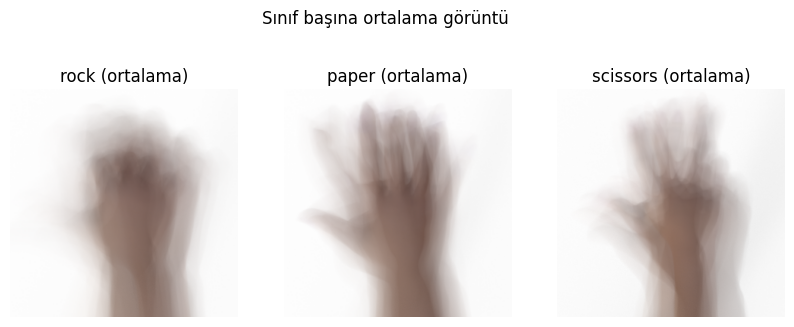

In [20]:
# --- İnceleme 3: Sınıf başına ortalama görüntü ---
# Her sınıf için tüm eğitim görüntülerinin piksel ortalaması hesaplanır (300x300x3).

toplam = np.zeros((3, 300, 300, 3), dtype=np.float64)
adet = np.zeros(3)

for image, label in ds_train:
    k = int(label.numpy())
    toplam[k] += image.numpy()
    adet[k] += 1

plt.figure(figsize=(10, 4))
for k in range(3):
    ortalama = (toplam[k] / adet[k]).astype("uint8")
    plt.subplot(1, 3, k + 1)
    plt.imshow(ortalama)
    plt.title(f"{class_names[k]} (ortalama)")
    plt.axis("off")
plt.suptitle("Sınıf başına ortalama görüntü")
plt.show()

**Gözlem 3 (ortalama görüntüler):**
- `rock` ortalaması tek, kompakt bir el kütlesi gibidir; belirgin parmak izi yoktur (kapalı yumruk).
- `paper` ortalamasında parmaklar yelpaze gibi açık ve geniş görünür; baş parmak yana doğru uzanır.
- `scissors` ortalaması ise iki sınıfın arasında kalır: parmak çizgileri vardır ama `paper` kadar geniş değildir.

**Keşif bulguları:**
1. Veri seti dengelidir; accuracy anlamlı bir metriktir.
2. Üç sınıf şekil olarak ayrışmaktadır; bu, problemin CNN için uygun olduğunu gösterir.
3. `scissors` sınıfı, ortalama görüntüde diğer iki sınıfın özelliklerini birlikte taşıdığı için karışmaya en yatkın sınıf olabilir. Bu bir hipotezdir; 7. ve 8. bölümlerde sonuçlarla karşılaştırılacaktır.
4. Arka planın sade olması görevi kolaylaştırır; sonuçlar gerçek dünya için iyimser olabilir.

---
## 4. Veri Ön İşleme (Yönerge 3.4)

| Adım | Uygulanan işlem | Neden |
|---|---|---|
| Yeniden boyutlandırma | 300x300 → **150x150** | Eğitimi hızlandırmak (GPU kullanılmadı) ve parametre sayısını azaltmak |
| Normalizasyon | Piksel değerleri 0–255 → **0–1** (255'e bölme) | Sinir ağı eğitimi 0–1 aralığında daha kararlı çalışır |
| Veri bölme | Eğitim **2.016** / validation **504** / test **372** | Eğitim setinin %20'si validation için ayrıldı; test seti hiç dokunulmadan son değerlendirme için saklandı |
| Karıştırma | `shuffle(seed=42)` | Bölmeden önce sırayı karıştırmak; tekrarlanabilirlik için sabit seed |
| Veri artırma | Yatay çevirme, ±%10 döndürme (RandomRotation 0.1), ±%10 yakınlaştırma | Eğitim çeşitliliğini artırıp ezberlemeyi azaltmak (model içinde, **yalnızca eğitimde** çalışır) |

**Uygulanmayanlar:** Eksik değer, aykırı değer ve encoding adımları gerekmedi, çünkü veri görüntüdür ve etiketler zaten tam sayıdır.

**Önemli sınırlılık:** Veri setinde "hangi görüntü hangi ele ait" bilgisi yoktur. Aynı elin farklı pozları hem eğitim hem validation tarafına düşmüş olabilir. Bu nedenle validation sonuçları **iyimser** olabilir; asıl güvenilir ölçü, hiç görülmemiş **test setidir**.

In [21]:
# --- Ön işleme ---
# IMG: görüntülerin yeni kenar uzunluğu, BATCH: her adımda işlenen görüntü sayısı.
# hazirla(): görüntüyü küçültür ve piksel değerlerini 0-1 aralığına çeker.
# Eğitim setinin son %20'si (504) validation olarak ayrılır; test seti ayrı kalır.
# Çıktıdaki 'Bir batch şekli' ve 'Piksel aralığı' satırları dönüşümün doğru yapıldığını gösterir.

IMG = 150
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

def hazirla(image, label):
    image = tf.image.resize(image, (IMG, IMG))
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

tum = ds_train.shuffle(2520, seed=42, reshuffle_each_iteration=False)
val_ham = tum.take(504)
train_ham = tum.skip(504)

train_ds = train_ham.map(hazirla).shuffle(1000, seed=42).batch(BATCH).prefetch(AUTOTUNE)
val_ds = val_ham.map(hazirla).batch(BATCH).prefetch(AUTOTUNE)
test_ds = ds_test.map(hazirla).batch(BATCH).prefetch(AUTOTUNE)

print("Eğitim:", sum(1 for _ in train_ham))
print("Validation:", sum(1 for _ in val_ham))
print("Test:", sum(1 for _ in ds_test))

for goruntuler, etiketler in train_ds.take(1):
    print("Bir batch şekli:", goruntuler.shape)
    print("Piksel aralığı:", float(tf.reduce_min(goruntuler)), "-", float(tf.reduce_max(goruntuler)))

Eğitim: 2016
Validation: 504
Test: 372
Bir batch şekli: (32, 150, 150, 3)
Piksel aralığı: 0.03529411926865578 - 1.0


---
## 5. Model Seçimi ve Tasarımı (Yönerge 3.5)

### Neden CNN?
Girdi görüntü olduğu için **evrişimli sinir ağı (CNN)** tercih edildi. Evrişim (Conv2D) katmanları görüntüdeki kenar, şekil ve parmak düzeni gibi yerel örüntüleri öğrenir ve aynı filtreyi görüntünün her yerinde kullanır. Düz bir sinir ağına (yalnızca Dense) göre çok daha az parametreyle görüntüde çalışır. Yönergede de görüntü problemleri için CNN önerilmektedir.

### Mimari
| Katman | Görevi |
|---|---|
| RandomFlip, RandomRotation, RandomZoom | Veri artırma; yalnızca eğitim sırasında çalışır |
| Conv2D(32) + MaxPooling | Basit özellikler (kenar, köşe); boyutu yarıya indirir |
| Conv2D(64) + MaxPooling | Daha karmaşık şekiller |
| Conv2D(128) + MaxPooling | Parmak düzeni gibi üst düzey örüntüler |
| Flatten | Özellik haritalarını tek bir vektöre çevirir (36.992 değer) |
| Dropout(0.5) | Eğitimde nöronların yarısını rastgele kapatır; ezberlemeyi azaltır |
| Dense(128, ReLU) | Öğrenilen özellikleri birleştirir |
| Dense(3, **softmax**) | 3 sınıfın olasılıklarını verir (toplamları 1) |

### Seçimler
- **Aktivasyon:** Gizli katmanlarda **ReLU** (hızlı, yaygın); çıkışta **softmax** (3 sınıf olasılığı).
- **Loss:** `sparse_categorical_crossentropy`, çünkü etiketler tam sayıdır (0, 1, 2) ve sınıf sayısı 3'tür.
- **Optimizer:** **Adam**, varsayılan öğrenme oranıyla (0.001). Ayar gerektirmeden iyi çalışan yaygın bir seçimdir.
- **Metrik:** accuracy.
- **Parametre sayısı:** 4.828.739. Bunun yaklaşık %98'i (4.735.104) `Flatten` sonrasındaki `Dense(128)` katmanındadır; ezberleme riskinin kaynağı bu katmandır ve Dropout bu yüzden oraya konmuştur.

In [22]:
# --- Model tasarımı ---
# tf.random.set_seed(42): başlangıç ağırlıklarını mümkün olduğunca tekrarlanabilir yapar.
# Sequential: katmanlar sırayla dizilir.
# model.compile: optimizer (Adam), kayıp fonksiyonu ve izlenecek metrik tanımlanır.
# model.summary(): katman çıktı şekillerini ve parametre sayılarını gösterir.

from tensorflow.keras import layers, models

tf.random.set_seed(42)

model = models.Sequential([
    layers.Input(shape=(IMG, IMG, 3)),

    # Veri artırma (yalnızca eğitimde çalışır)
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),

    # Özellik çıkarma: 3 blok Conv2D + MaxPooling
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(),

    # Karar verme
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(3, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 150, 150, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,739 (18.42 MB)

 Trainable params: 4,828,739 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

---
## 6. Model Eğitimi (Yönerge 3.6)

| Ayar | Değer |
|---|---|
| Epoch | 10 |
| Batch size | 32 |
| Eğitim / validation | 2.016 / 504 görüntü (her epoch sonunda validation ölçülür) |
| Optimizer / öğrenme oranı | Adam / 0.001 |
| Donanım | CPU (GPU kullanılmadı) |
| Süre | Epoch başına yaklaşık 62–81 sn; toplam yaklaşık 11 dakika |

Her epoch'ta model eğitim verisinin tamamını bir kez görür. Epoch sonunda ayrılmış validation verisinde ölçüm yapılır; böylece modelin görmediği veride nasıl davrandığı izlenir. Hiperparametre ayarı (arama) yapılmadı; seçimler küçük ve basit bir başlangıç modeli olarak tutuldu.

In [23]:
# --- Eğitim ---
# model.fit: modeli train_ds üzerinde eğitir, her epoch sonunda val_ds'te doğrulama yapar.
# Her satırdaki accuracy/loss eğitim, val_accuracy/val_loss validation sonucudur.
# 'history' nesnesi, bir sonraki hücrede grafik çizmek için tüm epoch sonuçlarını saklar.

EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 73s 1s/step - accuracy: 0.4911 - loss: 1.0474 - val_accuracy: 0.7183 - val_loss: 0.6156
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 66s 1s/step - accuracy: 0.8775 - loss: 0.3672 - val_accuracy: 0.9762 - val_loss: 0.1175
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 66s 1s/step - accuracy: 0.9365 - loss: 0.1863 - val_accuracy: 0.9861 - val_loss: 0.0702
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - accuracy: 0.9534 - loss: 0.1346 - val_accuracy: 0.9940 - val_loss: 0.0316
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.9702 - loss: 0.0942 - val_accuracy: 0.9960 - val_loss: 0.0227
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 81s 996ms/step - accuracy: 0.9678 - loss: 0.0877 - val_accuracy: 0.9940 - val_loss: 0.0319
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 62s 975ms/step - accuracy: 0.9747 - loss: 0.0666 - val_accuracy: 1.0000 - val_loss: 0.0048
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 62s 985ms/step - accuracy: 0.9807 - loss: 0.0615 - val_accuracy: 0.9980 - 

### Eğitim eğrileri
Eğitim ve validation için accuracy ve loss grafikleri çizilir.

Tamamlanan epoch sayısı: 10


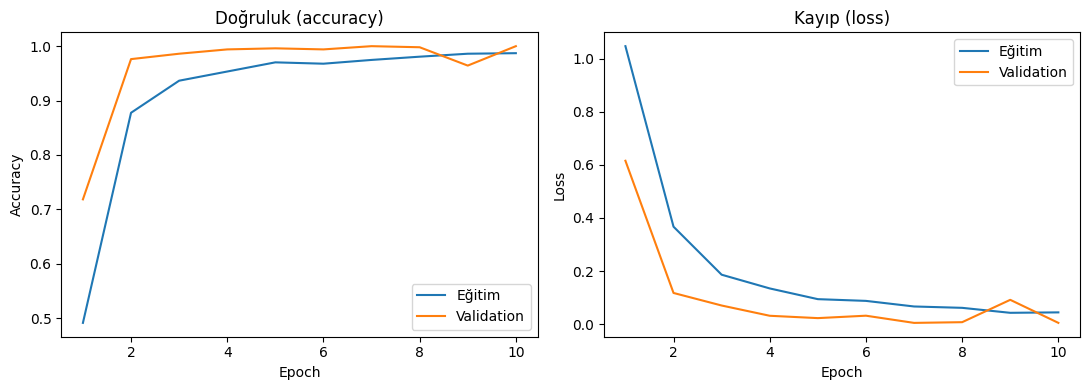

In [24]:
# --- Eğitim ve validation eğrileri ---
# history.history sözlüğünden her epoch'un accuracy ve loss değerleri alınıp çizilir.

print("Tamamlanan epoch sayısı:", len(history.history["accuracy"]))

epoch_araligi = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(epoch_araligi, history.history["accuracy"], label="Eğitim")
plt.plot(epoch_araligi, history.history["val_accuracy"], label="Validation")
plt.title("Doğruluk (accuracy)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epoch_araligi, history.history["loss"], label="Eğitim")
plt.plot(epoch_araligi, history.history["val_loss"], label="Validation")
plt.title("Kayıp (loss)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

**Eğitim eğrilerinin yorumu:**
- Eğitim doğruluğu 1. epoch'ta yaklaşık **%49**'dan başlayıp 3. epoch'ta yaklaşık %94'e, 10. epoch'ta yaklaşık **%98,7**'ye çıkmıştır. Kayıp ise yaklaşık 1,05'ten 0,04'e düşmüştür. Model öğrenmektedir.
- Validation doğruluğu çoğu epoch'ta eğitimden yüksektir. Bunun nedeni, eğitim sırasında Dropout ve veri artırmanın **açık**, validation'da ise **kapalı** olmasıdır; eğitim ölçümü daha zor koşulda yapılır.
- 9. epoch'ta validation'da geçici bir düşüş vardır (doğruluk yaklaşık %96,4, kayıp 0,092). Bu dalgalanma kararsız bir eğitime işaret etmez, ancak validation setinin küçük olduğunu (504) ve sonuçların epoch'tan epoch'a oynayabildiğini gösterir.
- 10. epoch'ta validation doğruluğunun %100 olması, modelin kusursuz olduğu anlamına gelmez. Validation verisi eğitim setinden ayrıldığı için eğitim görüntülerine çok benzer olabilir (4. bölümdeki sınırlılık). Asıl ölçü test setidir.

---
## 7. Model Değerlendirme (Yönerge 3.7)

Değerlendirme, modelin eğitimde ve validation'da **hiç görmediği 372 test görüntüsü** üzerinde yapılır. Kullanılan metrikler:

- **Accuracy:** Doğru tahminlerin oranı. Sınıflar dengeli olduğu için güvenilirdir.
- **Precision:** "Bu sınıf" dediği görüntülerin kaçı gerçekten o sınıf?
- **Recall:** Gerçekte o sınıftan olan görüntülerin kaçını yakaladı?
- **F1:** Precision ve recall'ın dengeli ortalaması.
- **Confusion matrix:** Hangi sınıfın hangisiyle karıştığını gösterir.

12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 226ms/step
Test accuracy: 0.9140  |  Test loss: 0.2605

              precision    recall  f1-score   support

        rock      0.902     0.968     0.934       124
       paper      1.000     0.879     0.936       124
    scissors      0.854     0.895     0.874       124

    accuracy                          0.914       372
   macro avg      0.919     0.914     0.914       372
weighted avg      0.919     0.914     0.914       372



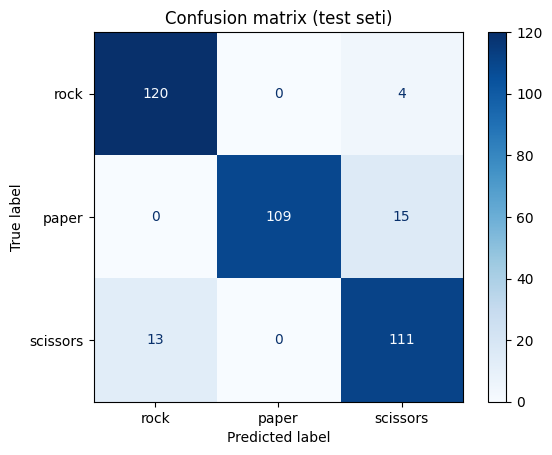

In [25]:
# --- Test seti değerlendirmesi ---
# model.predict: her test görüntüsü için 3 sınıfın olasılığını verir; argmax en yüksek olanı seçer.
# classification_report: sınıf bazında precision, recall ve F1 tablosunu yazdırır.
# confusion_matrix: satırlar gerçek sınıf, sütunlar tahmin edilen sınıftır.

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_gercek = np.concatenate([y.numpy() for _, y in test_ds])
olasiliklar = model.predict(test_ds)
y_tahmin = np.argmax(olasiliklar, axis=1)

test_kayip, test_dogruluk = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy: {test_dogruluk:.4f}  |  Test loss: {test_kayip:.4f}\n")

print(classification_report(y_gercek, y_tahmin, target_names=class_names, digits=3))

cm = confusion_matrix(y_gercek, y_tahmin)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
plt.title("Confusion matrix (test seti)")
plt.show()

**Test sonuçları:**

| Sınıf | Precision | Recall | F1 | Örnek |
|---|---|---|---|---|
| rock | 0,902 | 0,968 | 0,934 | 124 |
| paper | 1,000 | 0,879 | 0,936 | 124 |
| scissors | 0,854 | 0,895 | 0,874 | 124 |
| **Ortalama (macro)** | **0,919** | **0,914** | **0,914** | 372 |

**Genel:** Test accuracy **%91,40** (372 görüntünün 340'ı doğru), test loss **0,2605**.

**Confusion matrix:**

| Gerçek \ Tahmin | rock | paper | scissors |
|---|---|---|---|
| rock | **120** | 0 | 4 |
| paper | 0 | **109** | 15 |
| scissors | 13 | 0 | **111** |

**Yorum:**
- Toplam **32 hata** vardır (4 + 15 + 13). Hataların hiçbiri `rock` ile `paper` arasında değildir; **bütün karışıklıklar `scissors` sınıfının çevresinde** olmuştur. Bu, 3. bölümdeki hipotezle (scissors ortalama görüntüde diğer ikisinin özelliklerini taşıyor) uyumludur.
- `paper` için **precision 1,000**: model "paper" dediğinde hiç yanılmamıştır. Ancak **recall 0,879**: gerçek paper görüntülerinin 15'ini `scissors` sanmıştır. En çok kaçırılan sınıf paper'dır.
- `scissors` için precision en düşük (0,854): model fazla sayıda görüntüye (15 paper + 4 rock) "scissors" demiştir. F1'i de en düşük sınıf budur (0,874).
- `rock` en iyi recall'a sahiptir (0,968).

---
## 8. Sonuçların Yorumlanması ve Hata Analizi (Yönerge 3.8)

### 8.1 Yanlış tahmin edilen görüntüler
Aşağıdaki hücre, modelin yanlış tahmin ettiği görüntülerden ilk 12'sini; gerçek etiket, tahmin ve modelin **güven** değeriyle birlikte gösterir.

Yanlış tahmin sayısı: 32


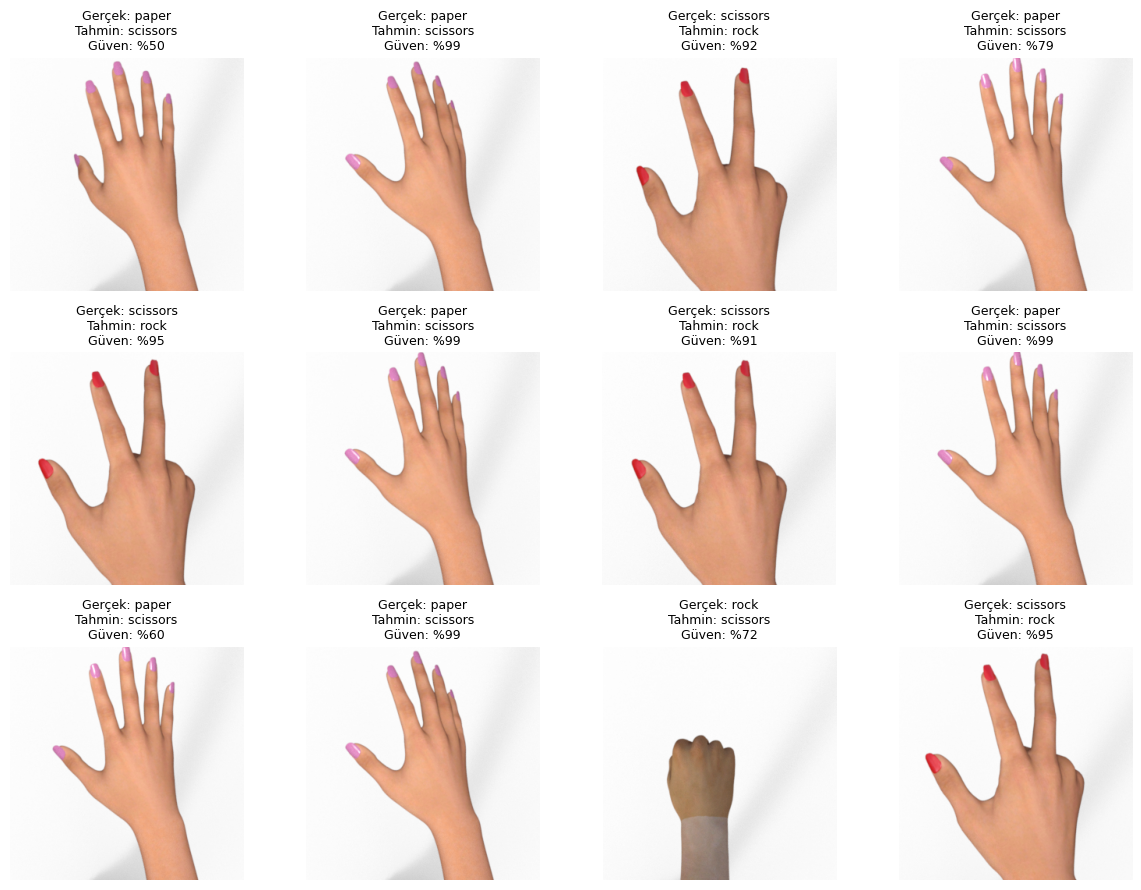

In [26]:
# --- Hata analizi: yanlış tahmin edilen görüntüler ---
# y_gercek != y_tahmin olan örneklerin indeksleri bulunur.
# Başlıkta modelin o tahmine ne kadar emin olduğu (en yüksek olasılık) yazılır.

test_goruntuler = [g.numpy() for g, _ in ds_test]
yanlis = np.where(y_gercek != y_tahmin)[0]
print("Yanlış tahmin sayısı:", len(yanlis))

plt.figure(figsize=(12, 9))
for i, idx in enumerate(yanlis[:12]):
    plt.subplot(3, 4, i + 1)
    plt.imshow(test_goruntuler[idx])
    guven = olasiliklar[idx].max() * 100
    plt.title(f"Gerçek: {class_names[y_gercek[idx]]}\nTahmin: {class_names[y_tahmin[idx]]}\nGüven: %{guven:.0f}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

**Hataların incelenmesi (gösterilen 12 görüntü, toplam 32 hatadan):**
- **Hatalar birkaç elde yoğunlaşıyor.** Aynı iki-üç el, farklı pozlarda tekrar tekrar yanlış tahmin edilmiştir: parmak uçları pembe tırnaklı, açık tenli bir `paper` eli ve kırmızı tırnaklı, açık tenli bir `scissors` eli. Hatalar rastgele dağılmış değildir.
- **Paper → scissors (15 hata):** Gösterilen `paper` hatalarında parmaklar birbirine yakındır ve bazıları diğerlerinden yüksektedir; bu duruş makası andırıyor olabilir.
- **Scissors → rock (13 hata):** Gösterilen `scissors` hatalarında el biraz dönmüş ve baş parmak dışarıda; iki parmak yukarıda olmasına rağmen model `rock` demiştir. Büyük olasılıkla bu eğik duruş modelin gördüğü örneklerden farklıdır.
- **Modelin güveni:** Birçok hatada model %91–99 emin olmasına rağmen yanılmıştır. Yani model **aşırı özgüvenlidir**; yüksek olasılık, tahminin doğru olduğunu garanti etmez. Az sayıda hatada (%50–79) tereddüt görülmektedir.
- **Rock → scissors** hatası yalnızca 4 tanedir; gösterilen örnekte bileğinde açık renkli bir bant olan, kapalı bir yumruk vardır (güven %72).

> **Olası nedenler (doğrulanmamış varsayımlar):** Bu elin/pozun eğitim setinde az temsil edilmesi, parmak duruşlarının makas şekline benzemesi, ten rengi ve tırnak boyası gibi alakasız görsel özelliklere modelin dayanmış olması. Bunları kesinleştirmek için daha fazla deney (örneğin hata yapılan elleri eğitim setinde sayma) gerekir.

### 8.2 Eğitim ve test sonuçlarının karşılaştırılması (aşırı öğrenme kontrolü)
Eğitim verisi, test verisiyle aynı koşulda (veri artırma ve Dropout kapalı) yeniden ölçülür; böylece eğitim-test karşılaştırması adil olur.

In [27]:
# --- Aşırı öğrenme (overfitting) kontrolü ---
# Eğitim verisi artırma olmadan, model.evaluate ile test ile aynı koşulda ölçülür.
# Eğitim ile test arasındaki accuracy farkı genelleme boşluğunu gösterir.

egitim_ds = train_ham.map(hazirla).batch(BATCH)
egitim_kayip, egitim_dogruluk = model.evaluate(egitim_ds, verbose=0)
print(f"Eğitim accuracy: {egitim_dogruluk:.4f}  |  Eğitim loss: {egitim_kayip:.4f}")
print(f"Test accuracy:   {test_dogruluk:.4f}  |  Test loss:   {test_kayip:.4f}")
print(f"Fark (accuracy): {(egitim_dogruluk - test_dogruluk) * 100:.2f} puan")

Eğitim accuracy: 0.9955  |  Eğitim loss: 0.0085
Test accuracy:   0.9140  |  Test loss:   0.2605
Fark (accuracy): 8.16 puan


**Aşırı öğrenme yorumu:**

| | Accuracy | Loss |
|---|---|---|
| Eğitim (artırma/Dropout kapalı) | %99,55 | 0,0085 |
| **Test** | **%91,40** | **0,2605** |
| Fark | **8,16 puan** | yaklaşık 30 kat |

- Eğitimde neredeyse kusursuz, görülmemiş veride ise belirgin biçimde daha düşük bir başarı vardır. Bu, **orta düzeyde aşırı öğrenme (overfitting)** göstergesidir; model eğitim görüntülerine (ve içindeki ellere) fazla uyum sağlamıştır.
- Kayıp farkı, doğruluk farkından daha çarpıcıdır: model yanıldığı görüntülerde de yüksek güven verdiği için test kaybı yükselmiştir.
- Validation'daki %100'e güvenilmemelidir; validation verisi eğitim setinden ayrıldığı için bağımsız bir sınav değildir. **Dürüst başarı ölçüsü test accuracy'sidir: %91,4.**

---
## 9. Sonuç ve Geliştirme Önerileri

### Genel değerlendirme
Basit bir CNN, 10 epoch'ta CPU üzerinde yaklaşık 11 dakikada eğitilmiş ve hiç görmediği test görüntülerinde **%91,4 doğruluk**, **%91,4 macro F1** elde etmiştir. Sınıflar dengeli olduğu için bu sonuç güvenilir bir özettir.

### Güçlü yönler
- Sade, hızlı eğitilen ve açıklaması kolay bir model.
- `rock` ve `paper` sınıfları birbiriyle hiç karışmamıştır; `paper` için precision %100'dür.
- Veri seti dengeli olduğu için sonuçlar sınıf dengesizliğinden etkilenmemiştir.

### Zayıf yönler
- Eğitim ile test arasında yaklaşık 8 puanlık boşluk (aşırı öğrenme).
- Hatalar `scissors` çevresinde ve birkaç elde yoğunlaşmıştır; paper → scissors ile scissors → rock karışıklıkları öne çıkar.
- Model yanlış tahminlerde bile çok emindir (aşırı özgüven).
- Veri seti sade arka planlı, büyük olasılıkla render edilmiş görüntülerden oluşur; gerçek kamera görüntülerinde başarı bu kadar yüksek olmayabilir.
- Validation seti, eğitim setinden rastgele ayrıldığı için bağımsız değildir.

### Geliştirme önerileri
1. **Daha çeşitli veri:** Farklı eller, ten tonları, ışık ve arka planlar eklemek.
2. **Daha güçlü veri artırma:** Parlaklık, kontrast, kaydırma gibi dönüşümler eklemek.
3. **Erken durdurma (EarlyStopping) ve daha güçlü düzenleme:** Dropout oranını artırmak, `Dense(128)` katmanını küçültmek ya da L2 düzenlemesi eklemek.
4. **Transfer learning:** MobileNetV2 gibi hazır eğitilmiş bir modelle başlamak; küçük veri setlerinde genellikle daha iyi genelleme sağlar.
5. **Daha güvenilir doğrulama:** Aynı elin görüntülerini eğitim ve validation arasında ayıracak bir bölme yapmak (el kimliği bilgisi varsa) veya çapraz doğrulama kullanmak.
6. **Hiperparametre ayarı:** Öğrenme oranı, filtre sayısı, görüntü boyutu gibi ayarları sistematik denemek; GPU ile daha çok epoch eğitmek.

### Kaynaklar
- Laurence Moroney, *Rock, Paper, Scissors Dataset*, 2019. http://laurencemoroney.com/rock-paper-scissors-dataset
- TensorFlow Datasets: https://www.tensorflow.org/datasets/catalog/rock_paper_scissors
- Kullanılan kütüphaneler: TensorFlow/Keras, NumPy, Matplotlib, scikit-learn.